In [36]:
# Bibliotecas utilizadas

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Constantes utilizadas

pi = np.pi

# Funções de Bessel de segunda espécie #

A função de Bessel de segunda espécie, $Y_\alpha(t)$, constituem a segunda solução linearmente indepedente da equação de Bessel:

$$t^2\frac{d^2y}{{dt}^2} + t\frac{dy}{dt} + (t^2 - \alpha^2)y = 0\,,$$

isto é, a solução geral dessa equação, para qualquer $\alpha$ complexo, é da forma:

$$y(t) = AJ_\alpha(t) + BY_\alpha(t)\,.$$

Essas funções são dadas por:

$$Y_\alpha(t) = \frac{J_\alpha(t)\cos{(\alpha\pi)}-J_{-\alpha}(t)}{\sin{(\alpha\pi)}}\,.$$

Se $\alpha$ for um inteiro $n$, então $Y_n(t) = 0/0$. Para sair dessa indeterminação é feito o limite:

$$Y_n(t) = \lim_{\alpha\to n}Y_\alpha(t)\,.$$

## Visualizando as funções de Bessel de segunda espécie ##

In [37]:
def fatorial(n):
    if n == 0:
        return 1
    else:
        produto = 1
        for k in range(1, n + 1, 1):
            produto *= k
        return produto

def integrando_funcao_Gamma(x, z):
    exp = np.exp(-x)
    polinomio = np.power(x, z - 1)
    return polinomio * exp

def funcao_Gamma(Z):
    if np.isscalar(Z):
        Z = np.array([Z], dtype=float)
    resultados = []
    for z in Z:
        # Polos da função Gamma (0, -1, -2, ...)
        if z <= 0 and np.isclose(z, np.round(z), rtol=0, atol=1e-12):
            resultados.append(np.inf)
            continue

        # Desloca z para o intervalo [1, 2) onde a integral é suave e bem comportada, aproveitando a propriedade \Gamma(z+1) = z\Gamma(z)
        multiplicador = 1.0
        while z < 1:
            multiplicador /= z
            z += 1
        while z >= 2:
            z -= 1
            multiplicador *= z

        def f(x):
            return integrando_funcao_Gamma(x, z)
        resultado, erro = quad(f, 0, np.inf)
        resultados.append(resultado * multiplicador)

    resultados = np.array(resultados)
    if len(resultados) == 1:
        return resultados[0]
    return resultados

def J(t, alpha, M=50):
    if not (np.isscalar(alpha)):
        raise ValueError('\u03B1 deve ser um escalar')
    soma = 0
    for m in range(0, M + 1, 1):
        denominador2 = funcao_Gamma(m + alpha + 1)
        
        # Se Gamma divergir (polo), 1/Gamma = 0; pula o termo.
        if np.isinf(denominador2):
            continue

        sinal = (-1)**m
        denominador1 = fatorial(m)
        denominador = denominador1 * denominador2

        numerador = np.power(t / 2, 2 * m + alpha)

        soma += sinal * numerador / denominador

    return soma

def Y(t, alpha, M = 50):
    if not (np.isscalar(alpha)):
        raise ValueError('\u03B1 deve ser um escalar')

    # Se alpha for inteiro, aproxima o limite numericamente para evitar 0/0
    if np.isclose(alpha, np.round(alpha), rtol = 0, atol=1e-12):
        e = 1e-6
        return 0.5 * (Y(t,alpha+e,M) + Y(t, alpha-e,M))

    num = J(t,alpha,M)*np.cos(alpha*pi) - J(t,-alpha,M)
    den = np.sin(alpha*np.pi)
    return num / den

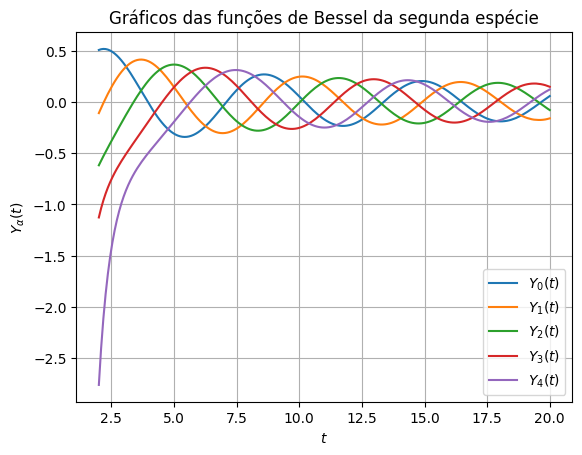

In [38]:
t0 = 2
tf = 20
M = 50

lista_alpha = [0,1,2,3,4]
t = np.linspace(t0, tf,201)

lista_Y = []
for alpha in lista_alpha:
    Y_alpha = Y(t,alpha,M)
    lista_Y.append(Y_alpha)

for k in range(0, len(lista_alpha),1):
    plt.plot(t, lista_Y[k], label = r'$Y_{%d}(t)$' %(lista_alpha[k]))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$Y_{\alpha}(t)$')
plt.title('Gráficos das funções de Bessel da segunda espécie')
plt.legend(loc = 'best')
plt.show()

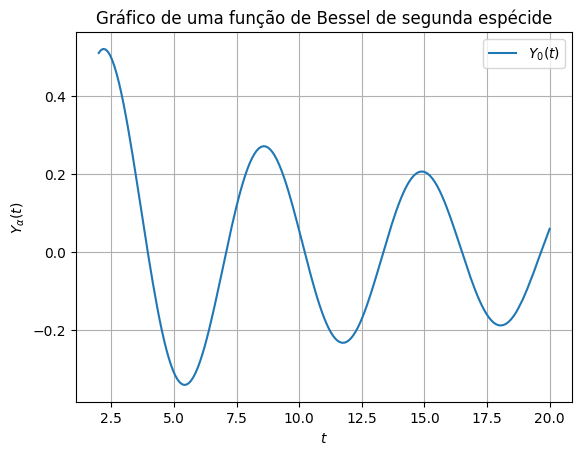

In [39]:
M = 50

alpha = 0
Y_alpha = Y(t, alpha, M)
plt.plot(t, Y_alpha, label = r'$Y_{%d}(t)$' %(alpha))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$Y_{\alpha}(t)$')
plt.title('Gráfico de uma função de Bessel de segunda espécide')
plt.legend(loc = 'best')
plt.show()

# Propriedades das funções de Bessel de segunda espécie #

A seguir, são apresentadas algumas propriedades das funções de Bessel de segunda espécie:

##### 1 - Recorrência algébrica

$$Y_{\alpha-1}(t)+Y_{\alpha+1}(t)=\frac{2\alpha}{t}Y_\alpha(t)\,.$$

##### 2 - Relação de Derivadas

$$Y_{\alpha-1}(t)-Y_{\alpha+1}(t)=2\frac{dY_\alpha(t)}{dt}\,.$$

##### 3 - Identidade operacional

$$\frac{d}{dt}\left[t^\alpha Y_\alpha(t)\right]=t^\alpha Y_{\alpha-1}(t)\,.$$

##### 4 - Comportamento na origem

Quando $t\to 0^{+}$:

1) Para $\alpha=0$:

$$Y_0(t)\approx\frac{2}{\pi}\ln{(t)}\,.$$

2) Para $\alpha>0$:

$$Y_\alpha(t)\approx-\frac{\Gamma(\alpha)}{\pi}\left(\frac{2}{t}\right)^\alpha\,.$$

dessa forma, $Y_\alpha(t)\to-\infty$ quando $t\to 0^{+}$.

##### 5 - Comportamento assintótico

Para $t\to\infty$, temos que:

$$Y_\alpha(t)\to\sqrt{\frac{2}{\pi t}}\sin{\left(t-\frac{\alpha\pi}{2}-\frac{\pi}{4}\right)}\,.$$

##### 6 - Relação de paridade

Para qualquer $n$ inteiro 

$$Y_{-n}(t)=(-1)^n Y_n(t)\,.$$

A relação de paridade pode ser observada a seguir:

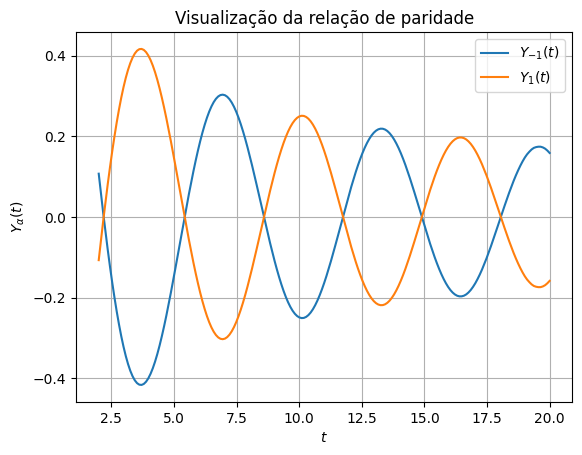

In [40]:
M = 50

n = 1

lista_alpha = [-n, n]

lista_Y = []
for alpha in lista_alpha:
    Y_alpha = Y(t,alpha,M)
    lista_Y.append(Y_alpha)

for k in range(0, len(lista_alpha),1):
    plt.plot(t, lista_Y[k], label = r'$Y_{%d}(t)$' %(lista_alpha[k]))
plt.grid(True)
plt.xlabel('$t$')
plt.ylabel(r'$Y_{\alpha}(t)$')
plt.title('Visualização da relação de paridade')
plt.legend(loc = 'best')
plt.show()